# BirdNET Transfer Learning

This notebook trains a classifier head on frozen BirdNET embeddings for Philippine eagle sound classification:
1. Loads 1,024-dimensional pre-trained feature embeddings extracted from **BirdNET (Cornell Lab of Ornithology)** in `notebooks/feature-extraction.ipynb`.
2. Splits the data by recording (70% Train, 15% Val, 15% Test), stratified by site for eagle recordings and by species for hard negatives, with the same function and seed as the CRNN-GRU training notebook, so both are evaluated on the same partitions.
3. Conducts **Leave-One-Site-Out (LOSO)** runs on Davao del Sur, on Cotabato, and on the four minor sites together, to measure generalization to sites the model has not heard.
4. Trains a **classifier head** on the embeddings with class-balanced weights. The head size, dropout, learning rate and input scaling are chosen by a search scored on the validation subset.
5. Performs full **INT8 post-training quantization** and measures compression ratio and edge inference latency.
6. Exports a performance table for the BirdNET models. Comparison with the other models is done in `experiments/model-benchmark/`.

## 1. Imports and Configuration

In [1]:
import json
import os
import re
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Random seed for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Configure GPU Memory Growth to prevent OOM
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f'Memory growth setting failed: {e}')

NOTEBOOK_ID = "birdnet-transfer-learning"

# Directory paths
CURRENT_PATH = Path.cwd()
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
MODELS_DIR = EXPERIMENT_DIR / "models"

DATA_DIR = PROJECT_ROOT / "data"
FEATURES_3S_DIR = DATA_DIR / "features" / "3-seconds"
BIRDNET_EMBED_DIR = FEATURES_3S_DIR / "birdnet-embeddings"
META_BN_PATH = FEATURES_3S_DIR / "birdnet_metadata.csv"
META_3S_PATH = DATA_DIR / "preprocessed" / "3-seconds" / "metadata.csv"

# Models and outputs directories


CM_DIR = OUTPUTS_DIR / "confusion-matrices"
HISTORY_DIR = OUTPUTS_DIR / "training-history"
FIGURES_DIR = OUTPUTS_DIR / "figures"

# Ensure all target directories exist
MODELS_DIR.mkdir(parents=True, exist_ok=True)
CM_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Training Hyperparameters
BATCH_SIZE = 32
EPOCHS = 40
LEARNING_RATE = 1e-3

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:          {PROJECT_ROOT}")
print(f"BirdNET embeddings:    {BIRDNET_EMBED_DIR}")
print(f"Models directory:      {MODELS_DIR}")
print(f"Outputs directory:     {OUTPUTS_DIR}")
print(f"TensorFlow Version:    {tf.__version__}")
print(f"Available GPUs:        {len(tf.config.list_physical_devices('GPU'))}")


I0000 00:00:1791816787.205895  277755 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791816787.244296  277755 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791816788.166059  277755 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root:          /home/fumei/Documents/MachineLearning/EagleSoundClassification
BirdNET embeddings:    /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/birdnet-embeddings
Models directory:      /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/models
Outputs directory:     /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs
TensorFlow Version:    2.21.0
Available GPUs:        1


## 2. Load Embeddings and Prepare Leak-Free Datasets

### 2.1. Ingest BirdNET Embeddings Metadata and Filter Clean Slices

In [2]:
# Load metadata catalog and align with physical embedding files
if META_BN_PATH.exists():
    df_meta = pd.read_csv(META_BN_PATH)
    # Build the embedding paths from the project root instead of the absolute paths stored in the CSV
    df_meta["embedding_path"] = df_meta["feature_file"].apply(lambda f: str(BIRDNET_EMBED_DIR / f))
elif META_3S_PATH.exists():
    df_raw_meta = pd.read_csv(META_3S_PATH)
    df_meta = df_raw_meta[~df_raw_meta["has_ambiguous"]].copy()
    if "slice_id" not in df_meta.columns and "file_name" in df_meta.columns:
        df_meta["slice_id"] = df_meta["file_name"].apply(lambda x: Path(x).stem)
    df_meta["embedding_path"] = df_meta["slice_id"].apply(lambda s: str(BIRDNET_EMBED_DIR / f"{s}.npy"))
else:
    raise FileNotFoundError("Metadata file not found. Run notebooks/preprocess.ipynb and feature-extraction.ipynb first.")

# Verify physical existence of .npy embedding files
df_meta["file_exists"] = df_meta["embedding_path"].apply(lambda p: os.path.exists(p))
df_clean = df_meta[df_meta["file_exists"]].copy().reset_index(drop=True)

initial_count = len(df_meta)
clean_count = len(df_clean)

print("=" * 65)
print("BIRDNET 1,024-D EMBEDDINGS DATASET INVENTORY")
print("=" * 65)
print(f"Cataloged Slices:           {initial_count}")
print(f"Verified Embeddings on Disk: {clean_count}")
print(f"Missing / Skipped Files:    {initial_count - clean_count}")
print(f"Philippine Eagle (1):       {(df_clean['label'] == 1).sum()} ({((df_clean['label'] == 1).mean()) * 100:.2f}%)")
print(f"No Eagle / Background (0):  {(df_clean['label'] == 0).sum()} ({((df_clean['label'] == 0).mean()) * 100:.2f}%)")
print(f"Unique Recording Sources:   {df_clean['source_audio'].nunique()}")
print(f"Recording Sites / States:   {df_clean['site'].unique().tolist()}")
print("=" * 65)

BIRDNET 1,024-D EMBEDDINGS DATASET INVENTORY
Cataloged Slices:           14421
Verified Embeddings on Disk: 14421
Missing / Skipped Files:    0
Philippine Eagle (1):       6674 (46.28%)
No Eagle / Background (0):  7747 (53.72%)
Unique Recording Sources:   562
Recording Sites / States:   ['Davao del Sur', 'Davao Oriental', 'Cotabato', 'Bukidnon', 'Misamis Oriental', 'Agusan del Sur', 'Singapore', 'Pingtung County', 'Unknown', 'Kerala', 'Chiayi City', 'Tamil Nadu', 'Quezon', 'Western', 'Zamboanga del Sur', 'New South Wales', 'Ilocos Norte', 'Karnataka', 'Samut Prakan', 'Sulawesi', 'Maharashtra', 'Goa', 'Kaohsiung City', 'Chiayi County', 'Taipei City', 'Western Australia', 'Rizal', 'Laguna', 'Kurunegala', 'Selangor', 'Matara', 'Tawi-Tawi', 'Nantou County', 'Bataan', 'Krung Thep Maha Nakhon [Bangkok]', 'Tripura', 'Samar', 'Taichung City', 'Taoyuan City', 'Uttarakhand', 'Fujian', 'Taitung County', 'Sylhet bibhag', 'Sandaun (West Sepik)', 'Bohol', 'Nakhon Nayok', 'Enga', 'Mountain Province',

### 2.2. Fast In-Memory Dataset Loader and Class Weights Helper

In [3]:
def load_embedding_arrays(df):
    """Load 1,024-D BirdNET float32 embeddings into an in-memory NumPy matrix."""
    n_samples = len(df)
    X = np.empty((n_samples, 1024), dtype=np.float32)
    
    for i, p in enumerate(df["embedding_path"]):
        X[i] = np.load(p)
        
    y = df["label"].values.astype(np.float32)
    return X, y


def get_balanced_class_weights(y_train):
    """Compute balanced class weights to prevent majority-class bias."""
    classes = np.unique(y_train)
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
    weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}
    return weight_dict

# Load full embedding feature matrix into memory
t0 = time.time()
X_all, y_all = load_embedding_arrays(df_clean)
load_time = time.time() - t0

print(f"Loaded {len(X_all)} BirdNET embeddings into RAM in {load_time:.2f} seconds.")
print(f"X_all Shape: {X_all.shape} (dtype: {X_all.dtype}) | Size: {X_all.nbytes / (1024*1024):.2f} MB")
print(f"y_all Shape: {y_all.shape} (dtype: {y_all.dtype})")

Loaded 14421 BirdNET embeddings into RAM in 0.69 seconds.
X_all Shape: (14421, 1024) (dtype: float32) | Size: 56.33 MB
y_all Shape: (14421,) (dtype: float32)


### 2.3. Recording-Level Split Helpers

In [4]:
def create_recording_split(df_clean, train_ratio=0.70, val_ratio=0.15, random_state=SEED):
    """
    Recording-level split: every source recording is assigned to exactly one subset.
    1. Recordings are grouped into strata: eagle recordings by site (the two main sites, and the
       smaller sites together) and hard-negative recordings by species.
    2. Within each stratum the recordings are shuffled and divided into Train, Val, and Test.
    3. All clips of a recording follow it. Augmented clips are kept only for Train recordings.
    Returns the train, val, and test indices and a table with the subset of every recording.
    """
    df_orig = df_clean[~df_clean["is_augmented"]]
    recordings = df_orig.groupby("source_audio").agg(
        dataset_source=("dataset_source", "first"),
        site=("site", "first"),
        species=("species", "first"),
        clips=("label", "size"),
        eagle_clips=("label", "sum"),
    ).reset_index()

    main_sites = {"Davao del Sur", "Cotabato"}
    is_eagle_recording = recordings["dataset_source"] == "eagle-audios"
    recordings["stratum"] = np.where(
        is_eagle_recording,
        "eagle | " + recordings["site"].where(recordings["site"].isin(main_sites), "other sites"),
        "hard negative | " + recordings["species"],
    )

    rng = np.random.default_rng(random_state)
    test_ratio = 1.0 - train_ratio - val_ratio
    assignment = {}
    for _, group in recordings.groupby("stratum", sort=True):
        names = rng.permutation(np.sort(group["source_audio"].values))
        n = len(names)
        n_test = max(1, int(round(n * test_ratio))) if n >= 3 else 0
        n_val = max(1, int(round(n * val_ratio))) if n >= 3 else 0
        for position, name in enumerate(names):
            assignment[name] = "test" if position < n_test else ("val" if position < n_test + n_val else "train")

    recordings["split"] = recordings["source_audio"].map(assignment)
    clip_split = df_clean["source_audio"].map(assignment).values
    is_aug = df_clean["is_augmented"].values

    train_idx = np.where(clip_split == "train")[0]
    val_idx = np.where((clip_split == "val") & ~is_aug)[0]
    test_idx = np.where((clip_split == "test") & ~is_aug)[0]
    return train_idx, val_idx, test_idx, recordings


def split_overlap_matrices(df_clean, train_idx, val_idx, test_idx):
    """Recordings and clips shared between each pair of subsets. The diagonal holds the size of each subset."""
    names = ["Train", "Val", "Test"]
    sources = df_clean["source_audio"].values
    clip_sets = [set(np.asarray(idx).tolist()) for idx in (train_idx, val_idx, test_idx)]
    recording_sets = [set(sources[np.asarray(idx)]) for idx in (train_idx, val_idx, test_idx)]
    recording_overlap = pd.DataFrame([[len(a & b) for b in recording_sets] for a in recording_sets], index=names, columns=names)
    clip_overlap = pd.DataFrame([[len(a & b) for b in clip_sets] for a in clip_sets], index=names, columns=names)
    return recording_overlap, clip_overlap


def assert_no_leakage(df_clean, train_idx, val_idx, test_idx):
    """Stop with an error if a recording or a clip is in two subsets, or if an augmented clip is outside Train."""
    recording_overlap, clip_overlap = split_overlap_matrices(df_clean, train_idx, val_idx, test_idx)
    off_diagonal = lambda m: int(m.values.sum() - np.trace(m.values))
    assert off_diagonal(recording_overlap) == 0, f"Recordings shared between subsets:\n{recording_overlap}"
    assert off_diagonal(clip_overlap) == 0, f"Clips shared between subsets:\n{clip_overlap}"

    is_aug = df_clean["is_augmented"].values
    sources = df_clean["source_audio"].values
    assert not is_aug[val_idx].any(), "Augmented clips found in Val"
    assert not is_aug[test_idx].any(), "Augmented clips found in Test"
    train_original_recordings = set(sources[train_idx][~is_aug[train_idx]])
    assert set(sources[train_idx][is_aug[train_idx]]) <= train_original_recordings, "Augmented clip from a recording outside Train"
    return recording_overlap, clip_overlap


def create_loso_split(df_clean, holdout_site, val_ratio=0.15, random_state=SEED):
    """
    Leak-free Leave-One-Site-Out (LOSO) split:
    1. Test set consists ONLY of unaugmented samples from the holdout site (one site name or a list of sites).
    2. Remaining sites form the train pool (unaugmented).
    3. GroupShuffleSplit partitions train pool into Train and Val by source_audio.
    4. Augmented samples from training sources are injected ONLY into Train.
    5. Guarantees Val and Test have 0 augmented samples.
    """
    holdout_sites = [holdout_site] if isinstance(holdout_site, str) else list(holdout_site)

    orig_indices = np.where(~df_clean["is_augmented"].values)[0]
    df_orig = df_clean.iloc[orig_indices].reset_index(drop=True)

    test_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site in holdout_sites]
    test_idx = [orig_indices[i] for i in test_orig_sub_idx]

    pool_orig_sub_idx = [i for i, row in enumerate(df_orig.itertuples()) if row.site not in holdout_sites]
    df_pool = df_orig.iloc[pool_orig_sub_idx].reset_index(drop=True)
    pool_indices = [orig_indices[i] for i in pool_orig_sub_idx]

    gss = GroupShuffleSplit(n_splits=1, test_size=val_ratio, random_state=random_state)
    tr_sub, val_sub = next(gss.split(df_pool, df_pool["label"], df_pool["source_audio"]))

    orig_train_idx = [pool_indices[i] for i in tr_sub]
    val_idx = [pool_indices[i] for i in val_sub]

    train_sources = set(df_pool.iloc[tr_sub]["source_audio"])
    aug_indices = np.where(df_clean["is_augmented"].values)[0]
    train_aug_idx = [i for i in aug_indices if df_clean.iloc[i]["source_audio"] in train_sources]

    train_idx = orig_train_idx + train_aug_idx
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


## 3. Classifier Head Architecture and Training Utilities

### 3.1. Build Transfer Learning Classifier Head

In [5]:
# Head settings as first used. Section 4.2 searches over alternatives and keeps the best one on the validation subset.
DEFAULT_HEAD_CONFIG = {"hidden": (128, 32), "dropout": 0.3, "learning_rate": LEARNING_RATE, "standardize": False}
SELECTED_HEAD_CONFIG = dict(DEFAULT_HEAD_CONFIG)


def build_transfer_classifier_head(input_dim=1024, hidden=(128, 32), dropout=0.3, learning_rate=LEARNING_RATE, standardize=False, X_train=None):
    """
    Classifier head on the frozen 1,024-D BirdNET embedding.
    hidden:      sizes of the hidden layers; () gives a single output layer on the embedding.
    dropout:     rate after the first hidden layer (on the embedding when there is no hidden layer); a second hidden layer uses 0.1 less.
    standardize: scale every embedding dimension to zero mean and unit variance, measured on X_train.
    """
    model = keras.Sequential(name="birdnet_eagle_classifier_head")
    model.add(layers.Input(shape=(input_dim,), name="birdnet_embedding"))
    if standardize:
        assert X_train is not None, "X_train is needed to measure the mean and variance"
        model.add(layers.Normalization(mean=X_train.mean(axis=0), variance=np.maximum(X_train.var(axis=0), 1e-6), name="standardize"))
    if len(hidden) == 0:
        model.add(layers.Dropout(dropout, name="drop_1"))
    for k, units in enumerate(hidden, start=1):
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(1e-4), name=f"dense_{k}"))
        if k == 1:
            model.add(layers.BatchNormalization(name="bn_1"))
        model.add(layers.Dropout(max(dropout - 0.1 * (k - 1), 0.0), name=f"drop_{k}"))
    model.add(layers.Dense(1, activation="sigmoid", kernel_regularizer=regularizers.l2(1e-4) if len(hidden) == 0 else None, name="eagle_prob"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )
    return model


def build_selected_head(X_train):
    """Head with the settings selected in section 4.2, built with a fixed seed."""
    tf.keras.utils.set_random_seed(SEED)
    return build_transfer_classifier_head(X_train=X_train, **SELECTED_HEAD_CONFIG)


def head_config_label(config):
    """Short text for a head configuration, used in tables and figures."""
    hidden = "-".join(str(u) for u in config["hidden"]) if len(config["hidden"]) else "none"
    return f"hidden {hidden} | dropout {config['dropout']} | lr {config['learning_rate']:g} | {'standardized' if config['standardize'] else 'raw'}"


# Inspect the head as first used
sample_head = build_transfer_classifier_head(**DEFAULT_HEAD_CONFIG)
sample_head.summary()


I0000 00:00:1791816789.620525  277755 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4058 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "birdnet_eagle_classifier_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ eagle_prob (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 135,873 (530.75 KB)

 Trainable params: 135,617 (529.75 KB)

 Non-trainable params: 256 (1.00 KB)

### 3.2. INT8 Quantization and Edge Latency Evaluator

In [6]:
def quantize_to_int8(keras_model, X_train, tflite_path):
    """Post-training full integer (INT8) quantization using representative dataset."""
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]

    def representative_dataset():
        n_samples = min(500, len(X_train))
        indices = np.random.choice(len(X_train), n_samples, replace=False)
        for idx in indices:
            yield [X_train[idx:idx+1].astype(np.float32)]

    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_model = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_model)
    return tflite_path


def evaluate_tflite_model(tflite_path, X_test, y_test):
    """Evaluate INT8 quantized TFLite model on test set and measure edge inference latency."""
    try:
        interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
        interpreter.allocate_tensors()
    except RuntimeError as e:
        print(f"Default XNNPACK delegate initialization encountered notice: {e}. Fallback to builtin kernels...")
        interpreter = tf.lite.Interpreter(
            model_path=str(tflite_path),
            experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES
        )
        interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    preds = []
    start_time = time.time()
    for i in range(len(X_test)):
        sample = X_test[i:i+1]
        if input_scale > 0:
            sample_quant = np.clip(np.round(sample / input_scale) + input_zero_point, -128, 127).astype(np.int8)
        else:
            sample_quant = sample.astype(np.float32)

        interpreter.set_tensor(input_details["index"], sample_quant)
        interpreter.invoke()
        out = interpreter.get_tensor(output_details["index"]).ravel()[0]

        if output_scale > 0:
            prob = float((float(out) - output_zero_point) * output_scale)
        else:
            prob = float(out)
        preds.append(float(np.clip(prob, 0.0, 1.0)))

    elapsed = time.time() - start_time
    preds = np.array(preds)
    preds_binary = (preds >= 0.5).astype(int)

    acc = accuracy_score(y_test, preds_binary)
    prec = precision_score(y_test, preds_binary, zero_division=0)
    rec = recall_score(y_test, preds_binary, zero_division=0)
    f1 = f1_score(y_test, preds_binary, zero_division=0)
    roc_auc = roc_auc_score(y_test, preds)
    pr_auc = average_precision_score(y_test, preds)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_binary).ravel()

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "specificity": float(tn / (tn + fp)),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "inference_time_ms_per_sample": float((elapsed / len(X_test)) * 1000),
        "model_size_kb": float(os.path.getsize(tflite_path) / 1024),
        "predictions": preds
    }


### 3.3. Training Curves and Confusion Matrix Visualizers

In [7]:
def plot_training_history(history_dict, out_path, title_prefix="BirdNET Transfer Learning"):
    """Plot Loss, Accuracy, and ROC-AUC curves and export figure."""
    epochs_range = range(1, len(history_dict["loss"]) + 1)
    has_auc = any("auc" in k for k in history_dict.keys())
    ncols = 3 if has_auc else 2

    fig, axes = plt.subplots(1, ncols, figsize=(6 * ncols, 4.5))

    # Loss
    axes[0].plot(epochs_range, history_dict["loss"], "b-", label="Train Loss")
    axes[0].plot(epochs_range, history_dict["val_loss"], "r--", label="Val Loss")
    axes[0].set_title(f"{title_prefix}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_ylim(0.1, 1.0)
    axes[0].set_yticks(np.arange(0.1, 1.01, 0.1))
    axes[0].legend()

    # Accuracy
    axes[1].plot(epochs_range, history_dict["accuracy"], "b-", label="Train Acc")
    axes[1].plot(epochs_range, history_dict["val_accuracy"], "r--", label="Val Acc")
    axes[1].set_title(f"{title_prefix}: Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0.1, 1.0)
    axes[1].set_yticks(np.arange(0.1, 1.01, 0.1))
    axes[1].legend()

    # AUC
    if has_auc:
        auc_key = [k for k in history_dict.keys() if "auc" in k and not k.startswith("val")][0]
        val_auc_key = [k for k in history_dict.keys() if "val_auc" in k][0]
        axes[2].plot(epochs_range, history_dict[auc_key], "b-", label="Train AUC")
        axes[2].plot(epochs_range, history_dict[val_auc_key], "r--", label="Val AUC")
        axes[2].set_title(f"{title_prefix}: ROC-AUC")
        axes[2].set_xlabel("Epoch")
        axes[2].set_ylabel("AUC")
        axes[2].set_ylim(0.1, 1.0)
        axes[2].set_yticks(np.arange(0.1, 1.01, 0.1))
        axes[2].legend()

    plt.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"Saved training history figure to: {out_path}")
    plt.show()


# Folder for the text files with the statistics of each model and the summary table
STATISTICS_DIR = OUTPUTS_DIR / "statistics"
STATISTICS_DIR.mkdir(parents=True, exist_ok=True)


def statistics_file_name(exp_name):
    """File name for a model's statistics, built from its name: lower case, words joined by hyphens."""
    slug = re.sub(r"[^a-z0-9]+", "-", exp_name.lower().replace("3.0s", "3s")).strip("-")
    return f"{slug}-statistics.txt"


def evaluate_predictions(y_true, y_pred_prob, exp_name, output_cm_path):
    """Print classification report and save confusion matrix figure."""
    y_pred = (y_pred_prob >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_pred_prob)
    pr_auc = average_precision_score(y_true, y_pred_prob)

    report_text = "\n".join([
        "=" * 65,
        f"EVALUATION RESULTS: {exp_name}",
        "=" * 65,
        f"Accuracy:    {acc:.4f} ({acc*100:.2f}%)",
        f"Precision:   {prec:.4f} ({prec*100:.2f}%)",
        f"Recall:      {rec:.4f} ({rec*100:.2f}%)",
        f"F1-Score:    {f1:.4f} ({f1*100:.2f}%)",
        f"Specificity: {tn / (tn + fp):.4f} ({(tn / (tn + fp))*100:.2f}%)",
        f"ROC-AUC:     {roc_auc:.4f}",
        f"PR-AUC:      {pr_auc:.4f}",
        f"Confusion:   TN {tn} | FP {fp} | FN {fn} | TP {tp}",
        "=" * 65,
        classification_report(y_true, y_pred, target_names=["No Eagle (0)", "Eagle (1)"]),
    ])
    print(report_text)
    stats_path = STATISTICS_DIR / statistics_file_name(exp_name)
    stats_path.write_text(report_text + "\n")
    print(f"Saved statistics to: {stats_path}")

    # Confusion Matrix Plot
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Eagle (0)", "Eagle (1)"],
        yticklabels=["No Eagle (0)", "Eagle (1)"],
        ax=ax
    )
    ax.set_title(f"Confusion Matrix: {exp_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    fig.savefig(output_cm_path, dpi=300, bbox_inches="tight")
    print(f"Saved confusion matrix to: {output_cm_path}")
    plt.show()

    return {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "specificity": float(tn / (tn + fp)),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    }

## 4. Experiment 1: Recording Split (70% Train, 15% Val, 15% Test)

### 4.1. Split Recordings, Check for Leakage, and Compute Class Weights

In [8]:
# Recording-level split: same function and seed as the CRNN-GRU training notebook
train_idx_std, val_idx_std, test_idx_std, df_recordings = create_recording_split(df_clean)
rec_overlap_std, clip_overlap_std = assert_no_leakage(df_clean, train_idx_std, val_idx_std, test_idx_std)

X_train_std, y_train_std = X_all[train_idx_std], y_all[train_idx_std]
X_val_std, y_val_std = X_all[val_idx_std], y_all[val_idx_std]
X_test_std, y_test_std = X_all[test_idx_std], y_all[test_idx_std]

class_weights_std = get_balanced_class_weights(y_train_std)

print(f"Train Set: {len(X_train_std)} samples (Class 1: {(y_train_std==1).sum()}, Class 0: {(y_train_std==0).sum()})")
print(f"Val Set:   {len(X_val_std)} samples (Class 1: {(y_val_std==1).sum()}, Class 0: {(y_val_std==0).sum()})")
print(f"Test Set:  {len(X_test_std)} samples (Class 1: {(y_test_std==1).sum()}, Class 0: {(y_test_std==0).sum()})")
print(f"Balanced Class Weights: {class_weights_std}")

print("\nRecordings per subset:")
display(df_recordings.groupby(["dataset_source", "split"]).size().unstack(fill_value=0))
print("Recordings shared between subsets (diagonal = subset size):")
display(rec_overlap_std)
print("Clips shared between subsets (diagonal = subset size):")
display(clip_overlap_std)


Train Set: 10684 samples (Class 1: 4806, Class 0: 5878)
Val Set:   1794 samples (Class 1: 484, Class 0: 1310)
Test Set:  1009 samples (Class 1: 450, Class 0: 559)
Balanced Class Weights: {0: 0.9088125212657366, 1: 1.1115272575946733}

Recordings per subset:


split,test,train,val
dataset_source,,,
eagle-audios,8,43,8
hard-negatives,77,349,77


Recordings shared between subsets (diagonal = subset size):


,Train,Val,Test
Train,392,0,0
Val,0,85,0
Test,0,0,85


Clips shared between subsets (diagonal = subset size):


,Train,Val,Test
Train,10684,0,0
Val,0,1794,0
Test,0,0,1009


### 4.2. Search Classifier Head Settings on the Validation Subset

Loading saved search results from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/head-search.csv
Selected head:   hidden 128-32 | dropout 0.5 | lr 0.001 | standardized  (validation F1 0.8141)
First used head: hidden 128-32 | dropout 0.3 | lr 0.001 | raw  (validation F1 0.7836)


,config,val_f1,val_f1_std,val_precision,val_recall,val_accuracy,val_roc_auc,val_pr_auc,best_epoch,note
0,hidden 128-32 | dropout 0.5 | lr 0.001 | stand...,0.8141,0.0140,0.8971,0.7466,0.9082,0.9553,0.9086,3.0000,selected
1,hidden 64 | dropout 0.5 | lr 0.001 | standardized,0.8126,0.0188,0.8905,0.7479,0.9071,0.9451,0.9031,3.6667,
2,hidden none | dropout 0.5 | lr 0.001 | standar...,0.8080,0.0068,0.8996,0.7335,0.9060,0.9446,0.8980,8.3333,
3,hidden none | dropout 0.3 | lr 0.001 | standar...,0.8055,0.0114,0.8934,0.7335,0.9045,0.9413,0.8943,7.6667,
4,hidden 64 | dropout 0.3 | lr 0.001 | standardized,0.8027,0.0235,0.8899,0.7328,0.9032,0.9418,0.8985,2.6667,
5,hidden none | dropout 0.5 | lr 0.001 | raw,0.8011,0.0078,0.9051,0.7190,0.9038,0.9489,0.9018,17.0000,
6,hidden 64 | dropout 0.3 | lr 0.0001 | raw,0.7979,0.0042,0.8842,0.7273,0.9006,0.9377,0.8907,4.6667,
7,hidden 128-32 | dropout 0.3 | lr 0.0001 | raw,0.7963,0.0117,0.8929,0.7197,0.9008,0.9422,0.8916,3.3333,
8,hidden 128-32 | dropout 0.3 | lr 0.001 | stand...,0.7954,0.0423,0.8954,0.7176,0.9012,0.9499,0.9001,1.0000,
9,hidden 64 | dropout 0.3 | lr 0.001 | raw,0.7951,0.0409,0.8329,0.7610,0.8943,0.9338,0.8822,2.0000,


Saved head search figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/figures/head-search-validation-f1.png


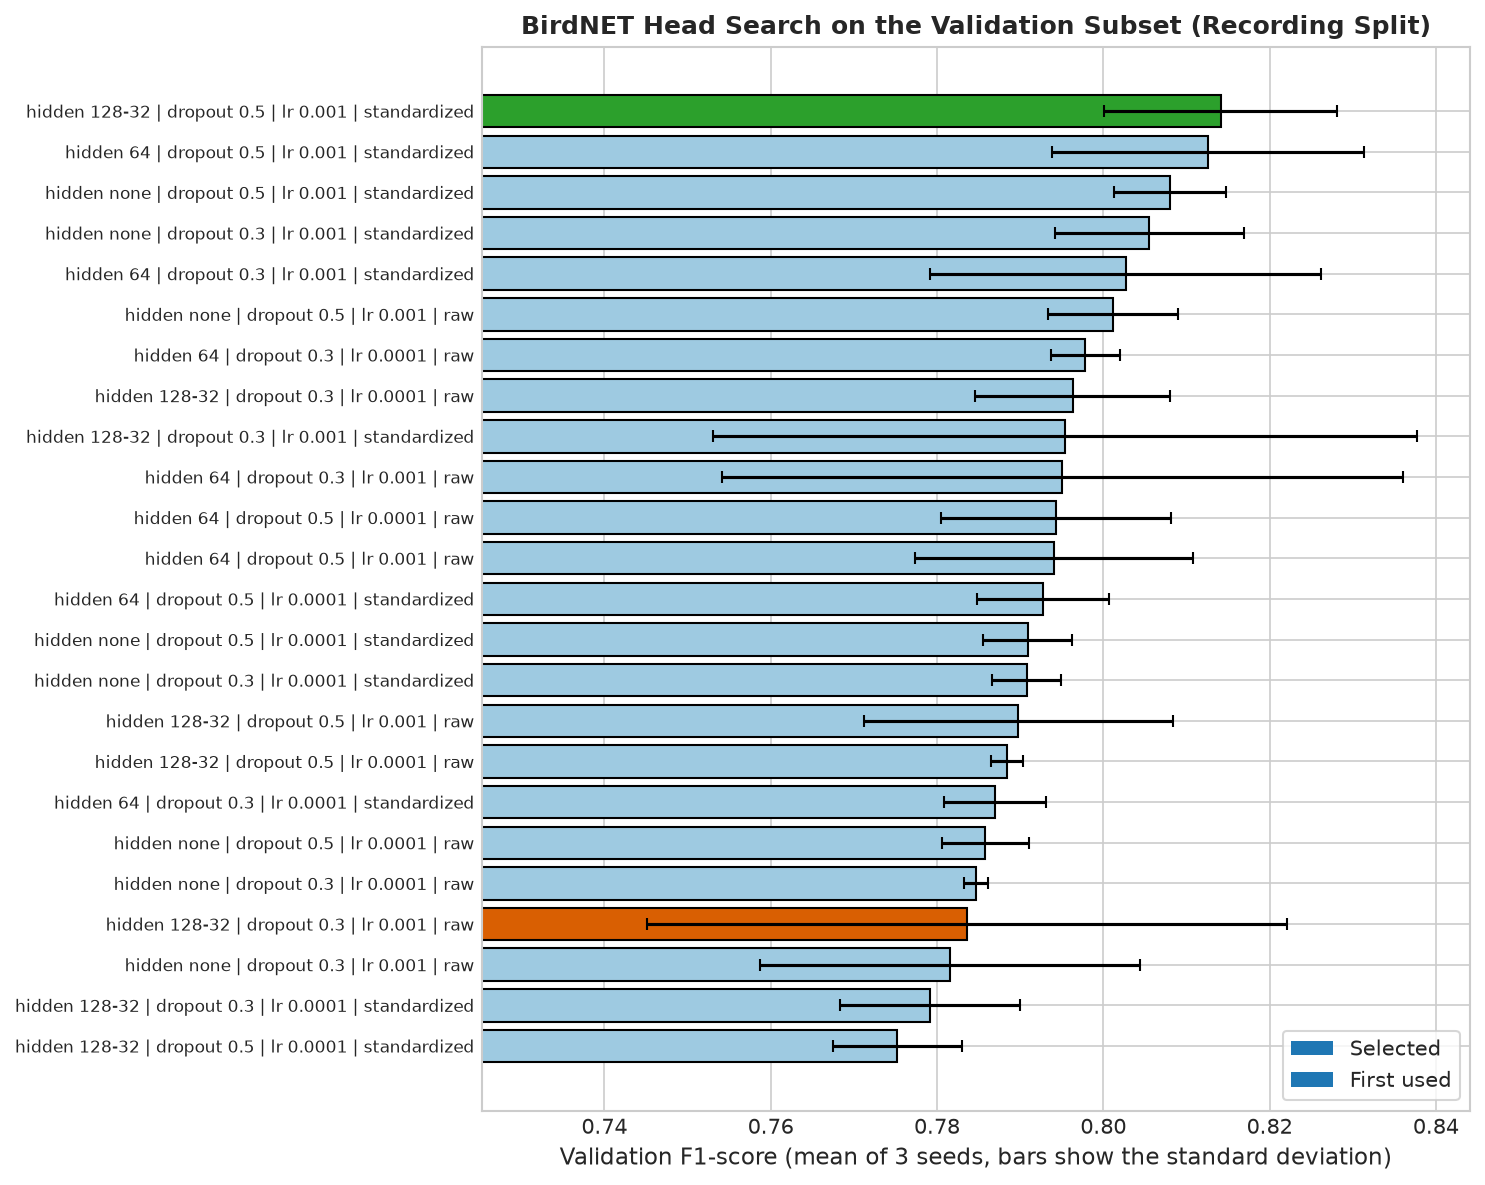

Saved head search table to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/statistics/birdnet-head-search.txt


In [9]:
# Search over head settings. Every setting is scored on the validation subset only; the test subset is not used here.
# The results are saved and reused. To run the search again, delete the CSV named below.
search_csv_path = OUTPUTS_DIR / "head-search.csv"
SEARCH_SEEDS = [42, 43, 44]
SEARCH_GRID = [
    {"hidden": hidden, "dropout": dropout, "learning_rate": learning_rate, "standardize": standardize}
    for hidden in [(), (64,), (128, 32)]
    for dropout in [0.3, 0.5]
    for learning_rate in [1e-3, 1e-4]
    for standardize in [False, True]
]

if search_csv_path.exists():
    print(f"Loading saved search results from: {search_csv_path}")
    df_search_runs = pd.read_csv(search_csv_path)
else:
    search_rows = []
    for config in tqdm(SEARCH_GRID, desc="Head search"):
        for seed in SEARCH_SEEDS:
            keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed)
            model = build_transfer_classifier_head(X_train=X_train_std, **config)
            fit = model.fit(
                X_train_std, y_train_std,
                validation_data=(X_val_std, y_val_std),
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=class_weights_std,
                callbacks=[
                    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=0),
                    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=0)
                ],
                verbose=0
            )
            val_prob = model.predict(X_val_std, verbose=0).ravel()
            val_pred = (val_prob >= 0.5).astype(int)
            search_rows.append({
                "config": head_config_label(config),
                "hidden": "-".join(str(u) for u in config["hidden"]) if len(config["hidden"]) else "none",
                "dropout": config["dropout"],
                "learning_rate": config["learning_rate"],
                "standardize": config["standardize"],
                "seed": seed,
                "val_f1": f1_score(y_val_std, val_pred, zero_division=0),
                "val_precision": precision_score(y_val_std, val_pred, zero_division=0),
                "val_recall": recall_score(y_val_std, val_pred, zero_division=0),
                "val_accuracy": accuracy_score(y_val_std, val_pred),
                "val_roc_auc": roc_auc_score(y_val_std, val_prob),
                "val_pr_auc": average_precision_score(y_val_std, val_prob),
                "best_epoch": int(np.argmin(fit.history["val_loss"])) + 1,
                "epochs_run": len(fit.history["val_loss"]),
            })
    df_search_runs = pd.DataFrame(search_rows)
    df_search_runs.to_csv(search_csv_path, index=False)
    print(f"Saved search results ({len(df_search_runs)} runs) to: {search_csv_path}")

# Average over the seeds and rank by validation F1-score (validation PR-AUC breaks ties)
df_search = df_search_runs.groupby(["config", "hidden", "dropout", "learning_rate", "standardize"], as_index=False).agg(
    val_f1=("val_f1", "mean"), val_f1_std=("val_f1", "std"), val_precision=("val_precision", "mean"), val_recall=("val_recall", "mean"),
    val_accuracy=("val_accuracy", "mean"), val_roc_auc=("val_roc_auc", "mean"), val_pr_auc=("val_pr_auc", "mean"), best_epoch=("best_epoch", "mean"),
).sort_values(["val_f1", "val_pr_auc"], ascending=False).reset_index(drop=True)
df_search["note"] = ""
df_search.loc[0, "note"] = "selected"
default_label = head_config_label(DEFAULT_HEAD_CONFIG)
df_search.loc[df_search["config"] == default_label, "note"] = df_search.loc[df_search["config"] == default_label, "note"].replace("", "first used").replace("selected", "selected, first used")

best = df_search.iloc[0]
SELECTED_HEAD_CONFIG = {
    "hidden": tuple(int(u) for u in str(best["hidden"]).split("-")) if str(best["hidden"]) != "none" else (),
    "dropout": float(best["dropout"]),
    "learning_rate": float(best["learning_rate"]),
    "standardize": bool(best["standardize"]),
}
first_used = df_search[df_search["config"] == default_label].iloc[0]
print(f"Selected head:   {head_config_label(SELECTED_HEAD_CONFIG)}  (validation F1 {best['val_f1']:.4f})")
print(f"First used head: {default_label}  (validation F1 {first_used['val_f1']:.4f})")
display(df_search.drop(columns=["hidden", "dropout", "learning_rate", "standardize"]).round(4))

# Figure: mean validation F1-score of every setting, with the spread over the seeds
fig, ax = plt.subplots(figsize=(10, 8))
plot_df = df_search.iloc[::-1]
bar_colors = ["#2ca02c" if "selected" in note else ("#d95f02" if "first used" in note else "#9ecae1") for note in plot_df["note"]]
ax.barh(plot_df["config"], plot_df["val_f1"], xerr=plot_df["val_f1_std"].fillna(0), color=bar_colors, edgecolor="black", capsize=3)
ax.set_xlim(max(plot_df["val_f1"].min() - 0.05, 0), min(plot_df["val_f1"].max() + 0.03, 1))
ax.set_xlabel("Validation F1-score (mean of 3 seeds, bars show the standard deviation)")
ax.set_title("BirdNET Head Search on the Validation Subset (Recording Split)", fontweight="bold")
ax.tick_params(axis="y", labelsize=8)
ax.barh([], [], color="#2ca02c", edgecolor="black", label="Selected")
ax.barh([], [], color="#d95f02", edgecolor="black", label="First used")
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
search_fig_path = FIGURES_DIR / "head-search-validation-f1.png"
fig.savefig(search_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved head search figure to: {search_fig_path}")
plt.show()

search_txt_path = STATISTICS_DIR / "birdnet-head-search.txt"
search_txt_path.write_text("\n".join([
    "=" * 80,
    "BIRDNET HEAD SEARCH ON THE VALIDATION SUBSET (RECORDING SPLIT)",
    f"{len(SEARCH_GRID)} settings, each trained with {len(SEARCH_SEEDS)} seeds. Values are means over the seeds. The test subset was not used.",
    "=" * 80,
    df_search.drop(columns=["hidden", "dropout", "learning_rate", "standardize"]).round(4).to_string(index=False),
    "",
    f"Selected head:   {head_config_label(SELECTED_HEAD_CONFIG)}",
    f"First used head: {default_label}",
    "",
]))
print(f"Saved head search table to: {search_txt_path}")


### 4.3. Train and Evaluate Recording Split Classifier Head (FP32)

Loading cached model from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/models/standard-split/birdnet-head-standard.keras
Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/training-history/standard-split-training-history.png


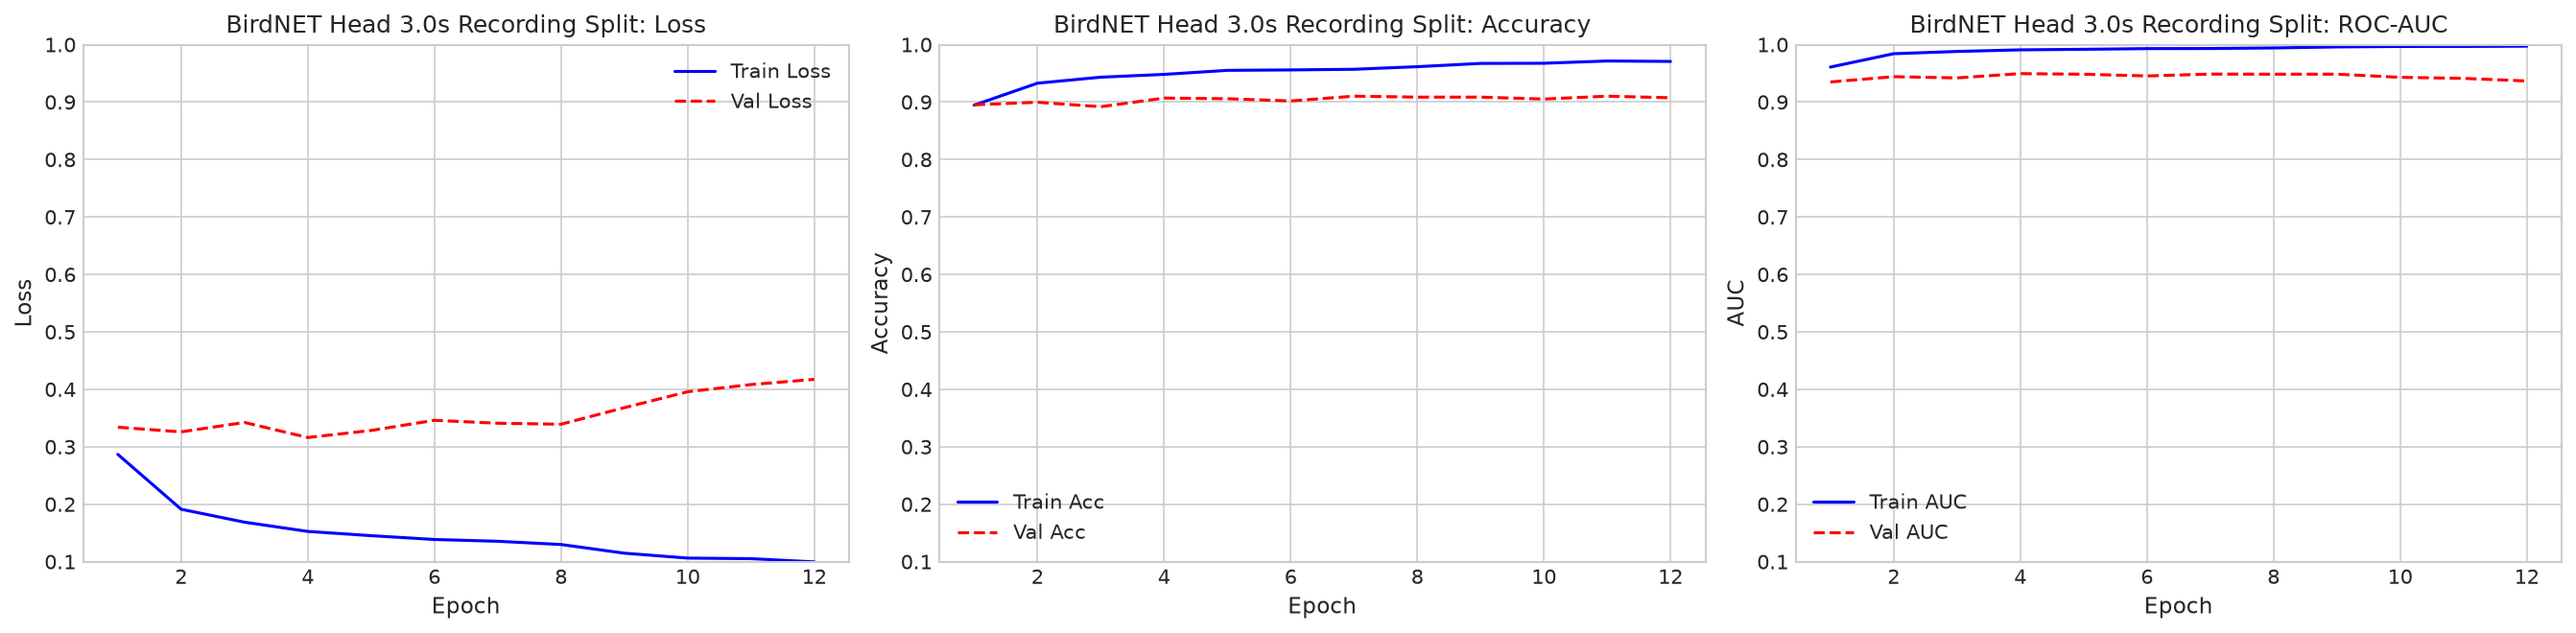

I0000 00:00:1791816792.495753  277841 service.cc:153] XLA service 0x7f361c062630 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791816792.495770  277841 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1791816792.499868  277841 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791816792.532372  277841 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1791816792.537217  277841 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


 1/32 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step

I0000 00:00:1791816793.535212  277841 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1791816793.836304  277838 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step
EVALUATION RESULTS: BirdNET Head 3.0s Recording Split
Accuracy:    0.9277 (92.77%)
Precision:   0.9374 (93.74%)
Recall:      0.8978 (89.78%)
F1-Score:    0.9171 (91.71%)
Specificity: 0.9517 (95.17%)
ROC-AUC:     0.9771
PR-AUC:      0.9705
Confusion:   TN 532 | FP 27 | FN 46 | TP 404
              precision    recall  f1-score   support

No Eagle (0)       0.92      0.95      0.94       559
   Eagle (1)       0.94      0.90      0.92       450

    accuracy                           0.93      1009
   macro avg       0.93      0.92      0.93      1009
weighted avg       0.93      0.93      0.93      1009

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/statistics/birdnet-head-3s-recording-split-statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/confusion-matrices/standa

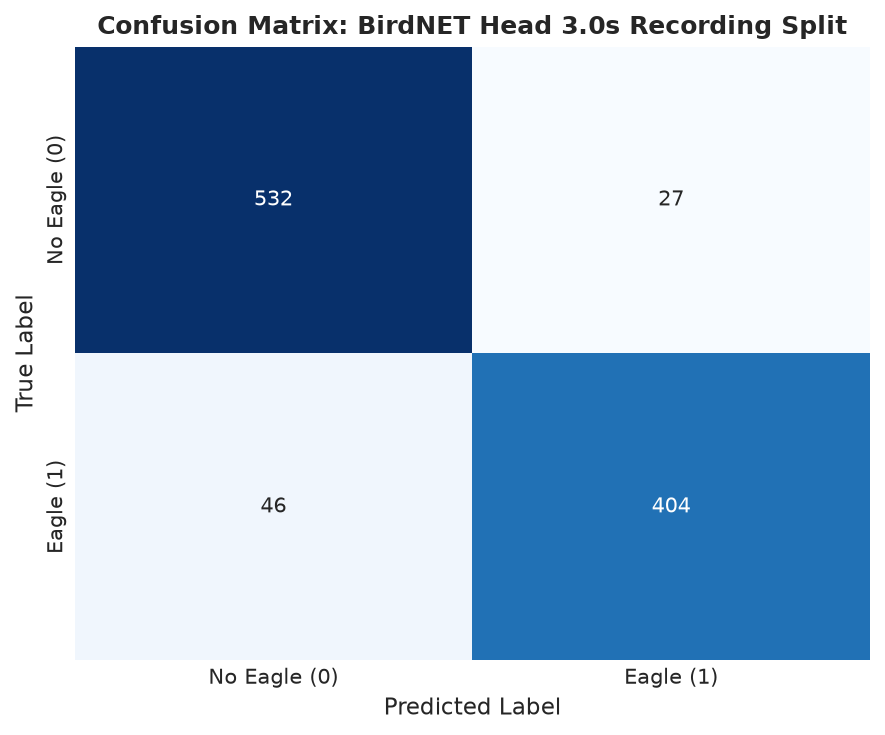

In [10]:
# Model paths
exp_std_dir = MODELS_DIR / "standard-split"
exp_std_dir.mkdir(parents=True, exist_ok=True)
model_std_path = exp_std_dir / "birdnet-head-standard.keras"
tflite_std_path = exp_std_dir / "birdnet-head-standard-int8.tflite"
history_std_path = exp_std_dir / "training_history.json"

if not model_std_path.exists():
    print("Training BirdNET transfer learning classifier head (Recording Split)...")
    model_std = build_selected_head(X_train_std)
    
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]
    
    t_start = time.time()
    fit_res = model_std.fit(
        X_train_std, y_train_std,
        validation_data=(X_val_std, y_val_std),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights_std,
        callbacks=callbacks,
        verbose=1
    )
    train_duration = time.time() - t_start
    print(f"Training completed in {train_duration:.2f} seconds!")
    
    model_std.save(model_std_path)
    history_std = {k: [float(v) for v in vals] for k, vals in fit_res.history.items()}
    with open(history_std_path, "w") as f:
        json.dump(history_std, f, indent=2)
else:
    print(f"Loading cached model from: {model_std_path}")
    model_std = keras.models.load_model(model_std_path)
    with open(history_std_path) as f:
        history_std = json.load(f)

# Visualize training curves
history_fig_std = HISTORY_DIR / "standard-split-training-history.png"
plot_training_history(history_std, history_fig_std, title_prefix="BirdNET Head 3.0s Recording Split")

# Evaluate FP32 model on Test Set
cm_std_path = CM_DIR / "standard-split-confusion-matrix.png"
y_pred_prob_std = model_std.predict(X_test_std).ravel()
res_std_fp32 = evaluate_predictions(y_test_std, y_pred_prob_std, "BirdNET Head 3.0s Recording Split", cm_std_path)

### 4.4. INT8 Quantization and Edge Benchmark (Recording Split)

In [11]:
# INT8 quantization and benchmark
if not tflite_std_path.exists():
    print("Performing INT8 post-training quantization...")
    quantize_to_int8(model_std, X_train_std, tflite_std_path)
    print(f"Saved INT8 model to: {tflite_std_path}")
else:
    print(f"Loading cached INT8 model: {tflite_std_path}")

res_std_int8 = evaluate_tflite_model(tflite_std_path, X_test_std, y_test_std)
fp32_size_kb = os.path.getsize(model_std_path) / 1024
int8_size_kb = res_std_int8["model_size_kb"]

print("=" * 65)
print("QUANTIZATION BENCHMARK: RECORDING SPLIT (classifier head only, BirdNET network not included)")
print("=" * 65)
print(f"FP32 Model Size:       {fp32_size_kb:.1f} KB")
print(f"INT8 Model Size:       {int8_size_kb:.1f} KB (Compression: {(1 - int8_size_kb/fp32_size_kb)*100:.1f}%)")
print(f"FP32 Test Accuracy:    {res_std_fp32['accuracy']*100:.2f}% | F1: {res_std_fp32['f1_score']*100:.2f}%")
print(f"INT8 Test Accuracy:    {res_std_int8['accuracy']*100:.2f}% | F1: {res_std_int8['f1_score']*100:.2f}%")
print(f"INT8 Head Latency / Sample (host computer): {res_std_int8['inference_time_ms_per_sample']:.3f} ms")
print("=" * 65)

Loading cached INT8 model: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/models/standard-split/birdnet-head-standard-int8.tflite


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


QUANTIZATION BENCHMARK: RECORDING SPLIT (classifier head only, BirdNET network not included)
FP32 Model Size:       1669.5 KB
INT8 Model Size:       142.4 KB (Compression: 91.5%)
FP32 Test Accuracy:    92.77% | F1: 91.71%
INT8 Test Accuracy:    92.67% | F1: 91.61%
INT8 Head Latency / Sample (host computer): 0.030 ms


## 5. Geographic Generalization: Leave-One-Site-Out (LOSO) Validation

### 5.1. LOSO Experiment: Davao del Sur Holdout

LOSO Davao del Sur -> Train: 6627, Val: 892, Test: 4964
Test Class Balance -> Eagle: 1692, Background: 3272
Loading cached LOSO Davao model: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/models/loso-davao/birdnet-head-loso-davao.keras
Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/training-history/loso-davao-training-history.png


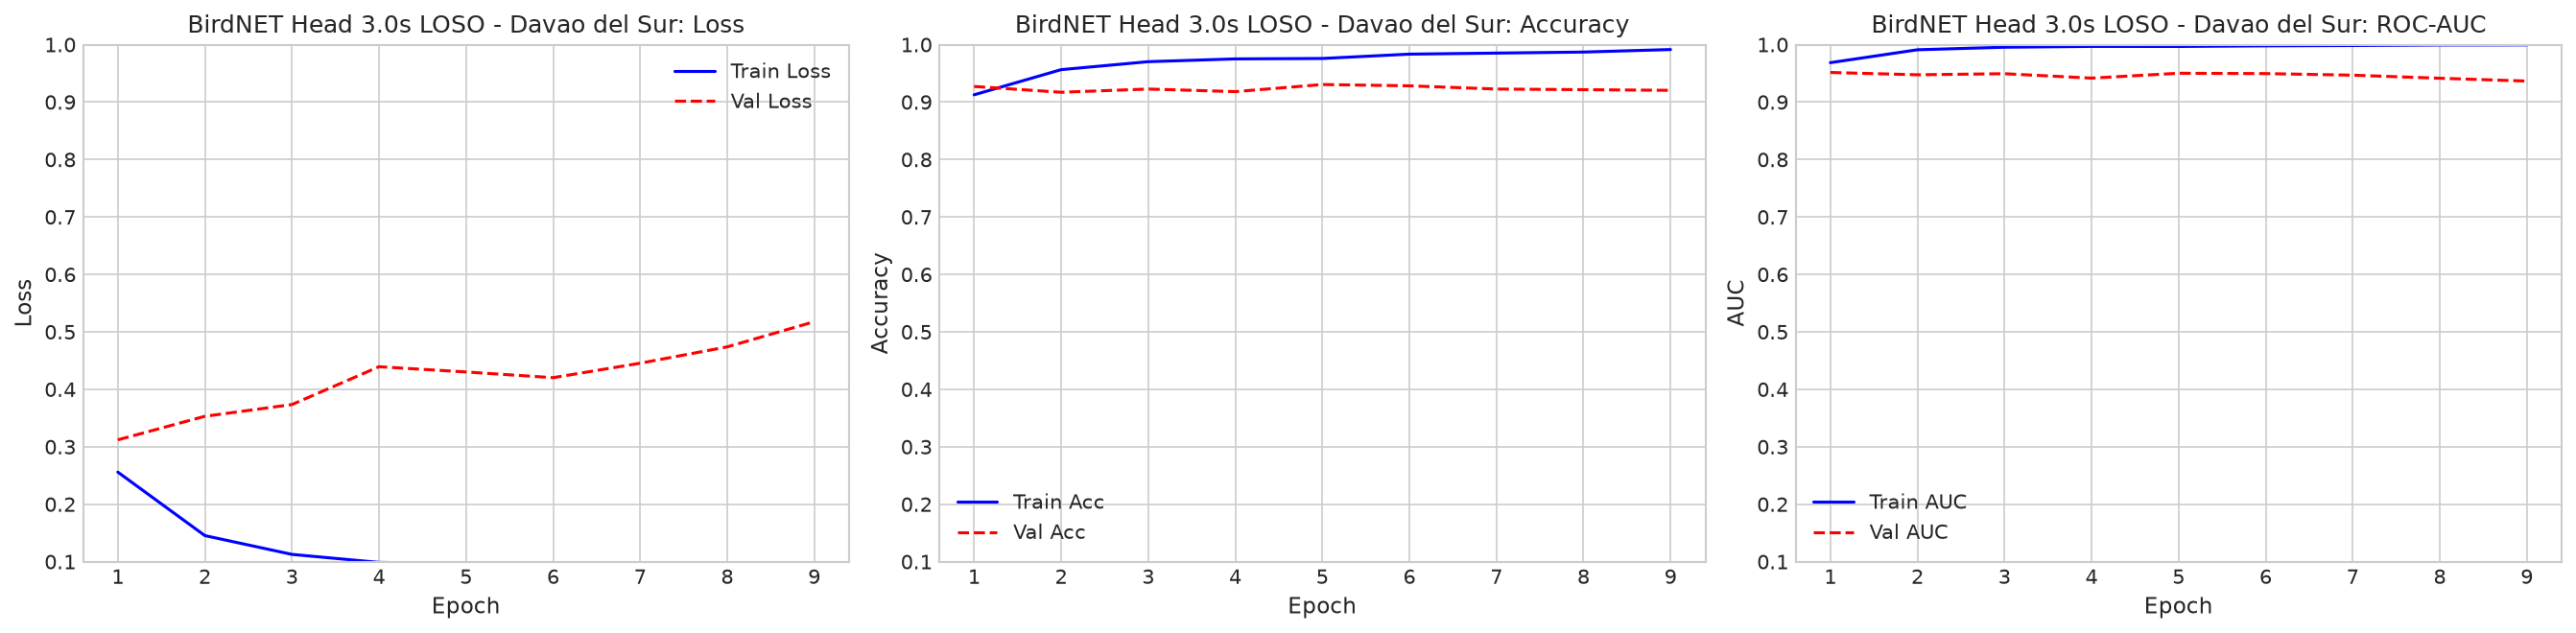

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
EVALUATION RESULTS: BirdNET Head 3.0s LOSO - Davao del Sur
Accuracy:    0.7832 (78.32%)
Precision:   0.9302 (93.02%)
Recall:      0.3936 (39.36%)
F1-Score:    0.5532 (55.32%)
Specificity: 0.9847 (98.47%)
ROC-AUC:     0.8252
PR-AUC:      0.7818
Confusion:   TN 3222 | FP 50 | FN 1026 | TP 666
              precision    recall  f1-score   support

No Eagle (0)       0.76      0.98      0.86      3272
   Eagle (1)       0.93      0.39      0.55      1692

    accuracy                           0.78      4964
   macro avg       0.84      0.69      0.71      4964
weighted avg       0.82      0.78      0.75      4964

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/statistics/birdnet-head-3s-loso-davao-del-sur-statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/confusion-mat

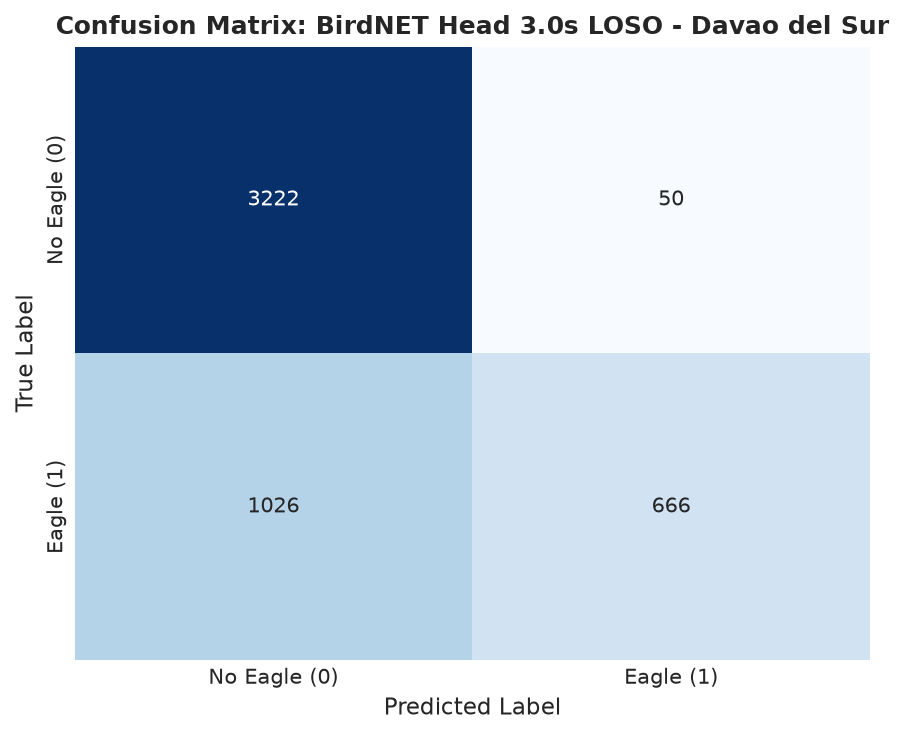

In [12]:
# Hold out all Davao del Sur recordings for testing (original clips only)
train_idx_davao, val_idx_davao, test_idx_davao = create_loso_split(df_clean, holdout_site="Davao del Sur", val_ratio=0.15, random_state=SEED)
assert_no_leakage(df_clean, train_idx_davao, val_idx_davao, test_idx_davao)

X_tr_d, y_tr_d = X_all[train_idx_davao], y_all[train_idx_davao]
X_val_d, y_val_d = X_all[val_idx_davao], y_all[val_idx_davao]
X_test_davao, y_test_davao = X_all[test_idx_davao], y_all[test_idx_davao]

class_weights_davao = get_balanced_class_weights(y_tr_d)

print(f"LOSO Davao del Sur -> Train: {len(X_tr_d)}, Val: {len(X_val_d)}, Test: {len(X_test_davao)}")
print(f"Test Class Balance -> Eagle: {(y_test_davao==1).sum()}, Background: {(y_test_davao==0).sum()}")

# Model paths
exp_davao_dir = MODELS_DIR / "loso-davao"
exp_davao_dir.mkdir(parents=True, exist_ok=True)
model_davao_path = exp_davao_dir / "birdnet-head-loso-davao.keras"
tflite_davao_path = exp_davao_dir / "birdnet-head-loso-davao-int8.tflite"
history_davao_path = exp_davao_dir / "training_history.json"

if not model_davao_path.exists():
    print("Training LOSO Davao model...")
    model_davao = build_selected_head(X_tr_d)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]
    fit_d = model_davao.fit(
        X_tr_d, y_tr_d,
        validation_data=(X_val_d, y_val_d),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights_davao,
        callbacks=callbacks,
        verbose=1
    )
    model_davao.save(model_davao_path)
    history_davao = {k: [float(v) for v in vals] for k, vals in fit_d.history.items()}
    with open(history_davao_path, "w") as f:
        json.dump(history_davao, f, indent=2)
else:
    print(f"Loading cached LOSO Davao model: {model_davao_path}")
    model_davao = keras.models.load_model(model_davao_path)
    with open(history_davao_path) as f:
        history_davao = json.load(f)

# Visualize training curves
history_fig_davao = HISTORY_DIR / "loso-davao-training-history.png"
plot_training_history(history_davao, history_fig_davao, title_prefix="BirdNET Head 3.0s LOSO - Davao del Sur")

# Evaluate FP32 and INT8
cm_davao_path = CM_DIR / "loso-davao-confusion-matrix.png"
y_prob_davao = model_davao.predict(X_test_davao).ravel()
res_davao_fp32 = evaluate_predictions(y_test_davao, y_prob_davao, "BirdNET Head 3.0s LOSO - Davao del Sur", cm_davao_path)

if not tflite_davao_path.exists():
    quantize_to_int8(model_davao, X_tr_d, tflite_davao_path)
res_davao_int8 = evaluate_tflite_model(tflite_davao_path, X_test_davao, y_test_davao)

### 5.2. LOSO Experiment: Cotabato Holdout

LOSO Cotabato -> Train: 7703, Val: 1491, Test: 3402
Test Class Balance -> Eagle: 1481, Background: 1921
Loading cached LOSO Cotabato model: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/models/loso-cotabato/birdnet-head-loso-cotabato.keras
Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/training-history/loso-cotabato-training-history.png


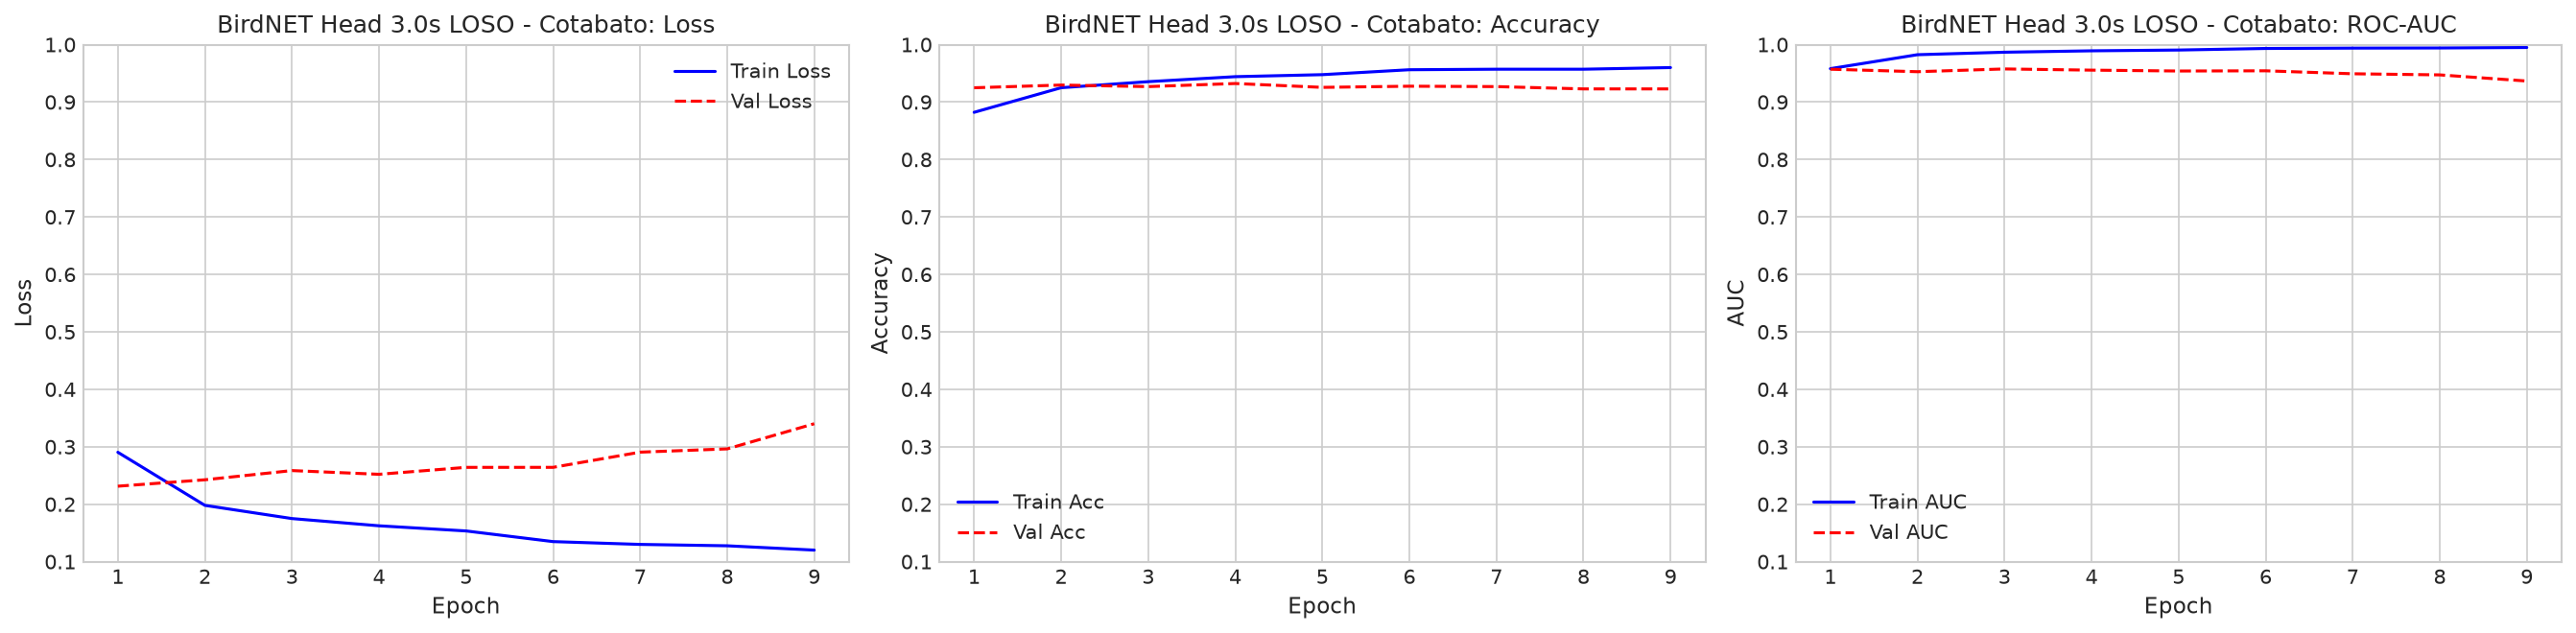

107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
EVALUATION RESULTS: BirdNET Head 3.0s LOSO - Cotabato
Accuracy:    0.8580 (85.80%)
Precision:   0.8574 (85.74%)
Recall:      0.8082 (80.82%)
F1-Score:    0.8321 (83.21%)
Specificity: 0.8964 (89.64%)
ROC-AUC:     0.9133
PR-AUC:      0.9114
Confusion:   TN 1722 | FP 199 | FN 284 | TP 1197
              precision    recall  f1-score   support

No Eagle (0)       0.86      0.90      0.88      1921
   Eagle (1)       0.86      0.81      0.83      1481

    accuracy                           0.86      3402
   macro avg       0.86      0.85      0.85      3402
weighted avg       0.86      0.86      0.86      3402

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/statistics/birdnet-head-3s-loso-cotabato-statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/confusion-matrices/los

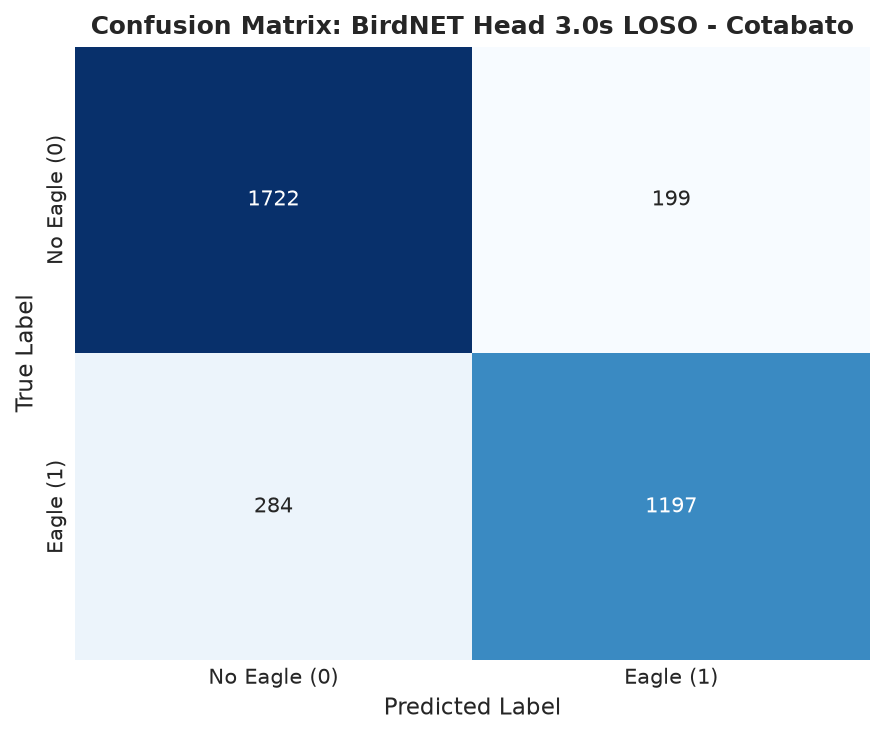

In [13]:
# Hold out all Cotabato recordings for testing (original clips only)
train_idx_cot, val_idx_cot, test_idx_cot = create_loso_split(df_clean, holdout_site="Cotabato", val_ratio=0.15, random_state=SEED)
assert_no_leakage(df_clean, train_idx_cot, val_idx_cot, test_idx_cot)

X_tr_c, y_tr_c = X_all[train_idx_cot], y_all[train_idx_cot]
X_val_c, y_val_c = X_all[val_idx_cot], y_all[val_idx_cot]
X_test_cot, y_test_cot = X_all[test_idx_cot], y_all[test_idx_cot]

class_weights_cot = get_balanced_class_weights(y_tr_c)

print(f"LOSO Cotabato -> Train: {len(X_tr_c)}, Val: {len(X_val_c)}, Test: {len(X_test_cot)}")
print(f"Test Class Balance -> Eagle: {(y_test_cot==1).sum()}, Background: {(y_test_cot==0).sum()}")

# Model paths
exp_cot_dir = MODELS_DIR / "loso-cotabato"
exp_cot_dir.mkdir(parents=True, exist_ok=True)
model_cot_path = exp_cot_dir / "birdnet-head-loso-cotabato.keras"
tflite_cot_path = exp_cot_dir / "birdnet-head-loso-cotabato-int8.tflite"
history_cot_path = exp_cot_dir / "training_history.json"

if not model_cot_path.exists():
    print("Training LOSO Cotabato model...")
    model_cot = build_selected_head(X_tr_c)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]
    fit_c = model_cot.fit(
        X_tr_c, y_tr_c,
        validation_data=(X_val_c, y_val_c),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights_cot,
        callbacks=callbacks,
        verbose=1
    )
    model_cot.save(model_cot_path)
    history_cot = {k: [float(v) for v in vals] for k, vals in fit_c.history.items()}
    with open(history_cot_path, "w") as f:
        json.dump(history_cot, f, indent=2)
else:
    print(f"Loading cached LOSO Cotabato model: {model_cot_path}")
    model_cot = keras.models.load_model(model_cot_path)
    with open(history_cot_path) as f:
        history_cot = json.load(f)

# Visualize training curves
history_fig_cot = HISTORY_DIR / "loso-cotabato-training-history.png"
plot_training_history(history_cot, history_fig_cot, title_prefix="BirdNET Head 3.0s LOSO - Cotabato")

# Evaluate FP32 and INT8
cm_cot_path = CM_DIR / "loso-cotabato-confusion-matrix.png"
y_prob_cot = model_cot.predict(X_test_cot).ravel()
res_cot_fp32 = evaluate_predictions(y_test_cot, y_prob_cot, "BirdNET Head 3.0s LOSO - Cotabato", cm_cot_path)

if not tflite_cot_path.exists():
    quantize_to_int8(model_cot, X_tr_c, tflite_cot_path)
res_cot_int8 = evaluate_tflite_model(tflite_cot_path, X_test_cot, y_test_cot)

### 5.3. LOSO Experiment: Minor Sites Holdout (Bukidnon, Davao Oriental, Agusan del Sur, Misamis Oriental)

LOSO Minor Sites -> Train: 12468, Val: 1105, Test: 364
Test Class Balance -> Eagle: 164, Background: 200
Loading cached LOSO Minor Sites model: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/models/loso-minor-sites/birdnet-head-loso-minor-sites.keras
Saved training history figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/training-history/loso-minor-sites-training-history.png


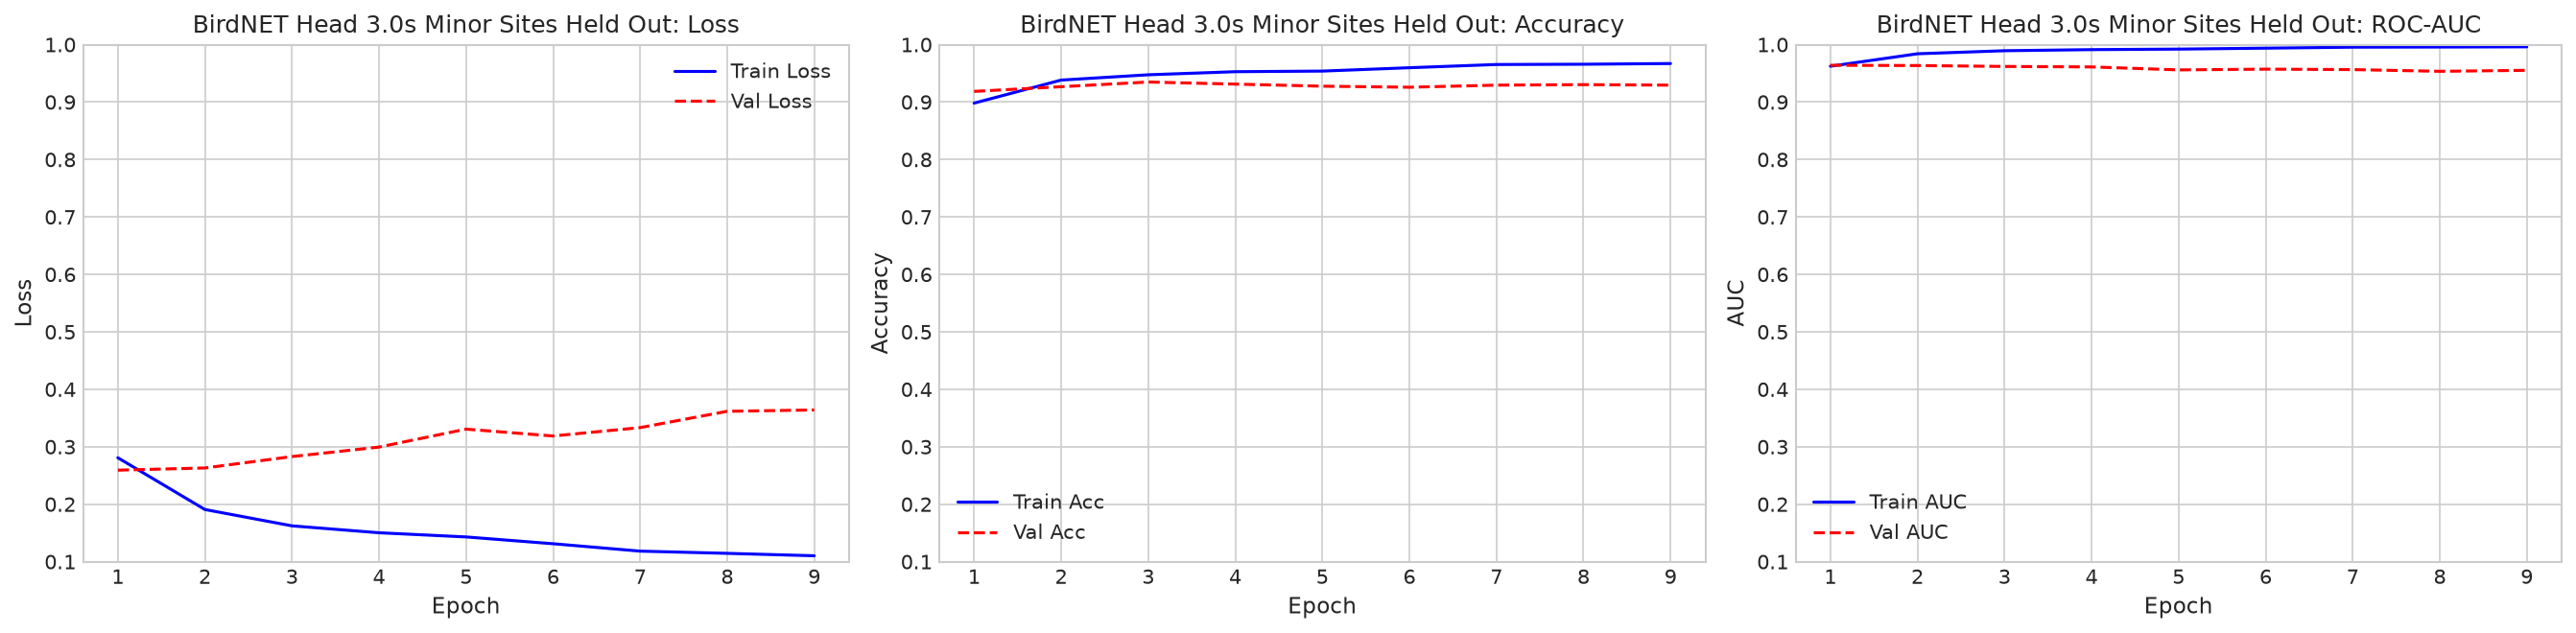

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step
EVALUATION RESULTS: BirdNET Head 3.0s Minor Sites Held Out
Accuracy:    0.8434 (84.34%)
Precision:   0.9652 (96.52%)
Recall:      0.6768 (67.68%)
F1-Score:    0.7957 (79.57%)
Specificity: 0.9800 (98.00%)
ROC-AUC:     0.9651
PR-AUC:      0.9595
Confusion:   TN 196 | FP 4 | FN 53 | TP 111
              precision    recall  f1-score   support

No Eagle (0)       0.79      0.98      0.87       200
   Eagle (1)       0.97      0.68      0.80       164

    accuracy                           0.84       364
   macro avg       0.88      0.83      0.83       364
weighted avg       0.87      0.84      0.84       364

Saved statistics to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/statistics/birdnet-head-3s-minor-sites-held-out-statistics.txt
Saved confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/confusion-matric

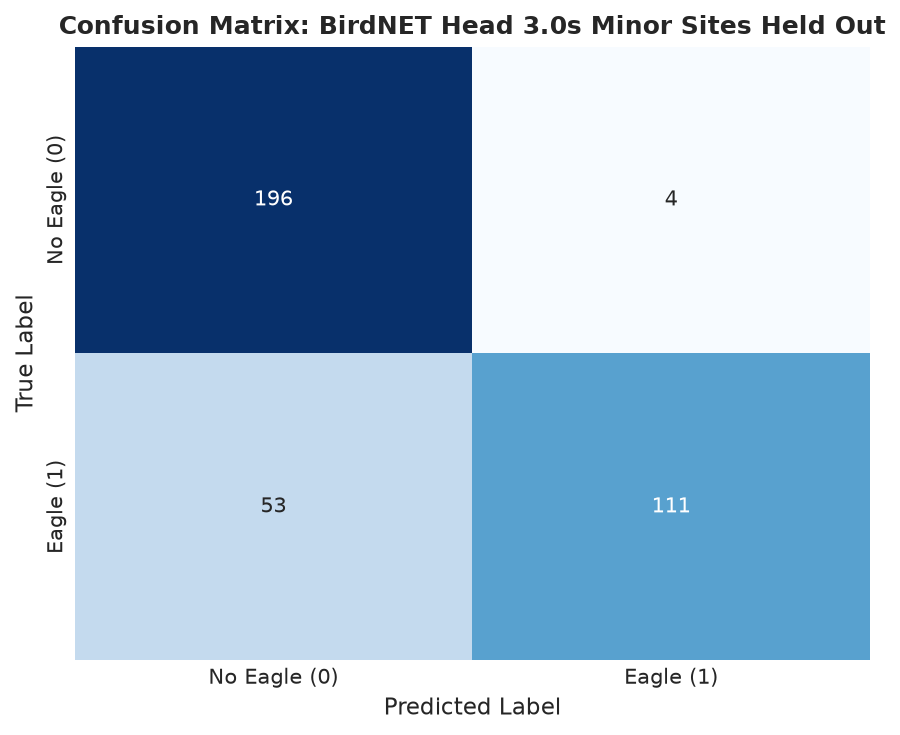

In [14]:
MINOR_SITES = ["Bukidnon", "Davao Oriental", "Agusan del Sur", "Misamis Oriental"]

# Hold out the four minor sites together for testing (original clips only)
train_idx_minor, val_idx_minor, test_idx_minor = create_loso_split(df_clean, holdout_site=MINOR_SITES, val_ratio=0.15, random_state=SEED)
assert_no_leakage(df_clean, train_idx_minor, val_idx_minor, test_idx_minor)

X_tr_m, y_tr_m = X_all[train_idx_minor], y_all[train_idx_minor]
X_val_m, y_val_m = X_all[val_idx_minor], y_all[val_idx_minor]
X_test_minor, y_test_minor = X_all[test_idx_minor], y_all[test_idx_minor]

class_weights_minor = get_balanced_class_weights(y_tr_m)

print(f"LOSO Minor Sites -> Train: {len(X_tr_m)}, Val: {len(X_val_m)}, Test: {len(X_test_minor)}")
print(f"Test Class Balance -> Eagle: {(y_test_minor==1).sum()}, Background: {(y_test_minor==0).sum()}")

# Model paths
exp_minor_dir = MODELS_DIR / "loso-minor-sites"
exp_minor_dir.mkdir(parents=True, exist_ok=True)
model_minor_path = exp_minor_dir / "birdnet-head-loso-minor-sites.keras"
tflite_minor_path = exp_minor_dir / "birdnet-head-loso-minor-sites-int8.tflite"
history_minor_path = exp_minor_dir / "training_history.json"

if not model_minor_path.exists():
    print("Training LOSO Minor Sites model...")
    model_minor = build_selected_head(X_tr_m)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]
    fit_m = model_minor.fit(
        X_tr_m, y_tr_m,
        validation_data=(X_val_m, y_val_m),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights_minor,
        callbacks=callbacks,
        verbose=1
    )
    model_minor.save(model_minor_path)
    history_minor = {k: [float(v) for v in vals] for k, vals in fit_m.history.items()}
    with open(history_minor_path, "w") as f:
        json.dump(history_minor, f, indent=2)
else:
    print(f"Loading cached LOSO Minor Sites model: {model_minor_path}")
    model_minor = keras.models.load_model(model_minor_path)
    with open(history_minor_path) as f:
        history_minor = json.load(f)

# Visualize training curves
history_fig_minor = HISTORY_DIR / "loso-minor-sites-training-history.png"
plot_training_history(history_minor, history_fig_minor, title_prefix="BirdNET Head 3.0s Minor Sites Held Out")

# Evaluate FP32 and INT8
cm_minor_path = CM_DIR / "loso-minor-sites-confusion-matrix.png"
y_prob_minor = model_minor.predict(X_test_minor).ravel()
res_minor_fp32 = evaluate_predictions(y_test_minor, y_prob_minor, "BirdNET Head 3.0s Minor Sites Held Out", cm_minor_path)

if not tflite_minor_path.exists():
    quantize_to_int8(model_minor, X_tr_m, tflite_minor_path)
res_minor_int8 = evaluate_tflite_model(tflite_minor_path, X_test_minor, y_test_minor)

## 6. BirdNET Performance Summary

### 6.1. Performance Summary Table

In [15]:
# Compile BirdNET transfer learning performance table
# Sizes and latency cover the classifier head only. The BirdNET network that produces the embeddings is not included.
benchmark_records = []

eval_configs = [
    ("Recording Split", "FP32", res_std_fp32, model_std_path),
    ("Recording Split", "INT8", res_std_int8, tflite_std_path),
    ("LOSO - Davao del Sur", "FP32", res_davao_fp32, model_davao_path),
    ("LOSO - Davao del Sur", "INT8", res_davao_int8, tflite_davao_path),
    ("LOSO - Cotabato", "FP32", res_cot_fp32, model_cot_path),
    ("LOSO - Cotabato", "INT8", res_cot_int8, tflite_cot_path),
    ("LOSO - Minor Sites", "FP32", res_minor_fp32, model_minor_path),
    ("LOSO - Minor Sites", "INT8", res_minor_int8, tflite_minor_path),
]

for exp_name, precision, res, model_path in eval_configs:
    benchmark_records.append({
        "Paradigm": "Transfer Learning",
        "Scale": "3.0s (1024)",
        "Architecture": "BirdNET + Head",
        "Experiment": exp_name,
        "Precision": precision,
        "Accuracy": float(res["accuracy"]),
        "Precision_Score": float(res["precision"]),
        "Recall": float(res["recall"]),
        "F1_Score": float(res["f1_score"]),
        "Specificity": float(res["specificity"]),
        "ROC_AUC": float(res["roc_auc"]),
        "PR_AUC": float(res["pr_auc"]),
        "Size_KB": os.path.getsize(model_path) / 1024,
        "Head_Latency_ms": res.get("inference_time_ms_per_sample", np.nan),
    })

df_birdnet = pd.DataFrame(benchmark_records)
out_csv = OUTPUTS_DIR / "multiscale-comparison.csv"
df_birdnet.to_csv(out_csv, index=False)
print(f"Saved BirdNET performance table to: {out_csv}")
display(df_birdnet)


Saved BirdNET performance table to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/multiscale-comparison.csv


,Paradigm,Scale,Architecture,Experiment,Precision,Accuracy,Precision_Score,Recall,F1_Score,Specificity,ROC_AUC,PR_AUC,Size_KB,Head_Latency_ms
0,Transfer Learning,3.0s (1024),BirdNET + Head,Recording Split,FP32,0.927651,0.937355,0.897778,0.917140,0.951699,0.977070,0.970506,1669.502930,NaN
1,Transfer Learning,3.0s (1024),BirdNET + Head,Recording Split,INT8,0.926660,0.935185,0.897778,0.916100,0.949911,0.974693,0.963910,142.367188,0.029904
2,Transfer Learning,3.0s (1024),BirdNET + Head,LOSO - Davao del Sur,FP32,0.783239,0.930168,0.393617,0.553156,0.984719,0.825177,0.781784,1669.475586,NaN
3,Transfer Learning,3.0s (1024),BirdNET + Head,LOSO - Davao del Sur,INT8,0.783642,0.923288,0.398345,0.556565,0.982885,0.823242,0.771885,142.367188,0.013908
4,Transfer Learning,3.0s (1024),BirdNET + Head,LOSO - Cotabato,FP32,0.858025,0.857450,0.808238,0.832117,0.896408,0.913310,0.911447,1669.482422,NaN
5,Transfer Learning,3.0s (1024),BirdNET + Head,LOSO - Cotabato,INT8,0.857143,0.849613,0.816340,0.832645,0.888600,0.913576,0.908767,142.367188,0.014448
6,Transfer Learning,3.0s (1024),BirdNET + Head,LOSO - Minor Sites,FP32,0.843407,0.965217,0.676829,0.795699,0.980000,0.965122,0.959520,1669.503906,NaN
7,Transfer Learning,3.0s (1024),BirdNET + Head,LOSO - Minor Sites,INT8,0.848901,0.965812,0.689024,0.804270,0.980000,0.964253,0.957381,142.367188,0.015952


### 6.2. Export Performance Summary to a Text File

In [16]:
# Write the summary table to its own text file, next to the per-model statistics files
summary_path = STATISTICS_DIR / "birdnet-performance-summary.txt"
summary_table = df_birdnet.drop(columns=["Paradigm", "Scale", "Architecture"]).copy()
for col in ["Accuracy", "Precision_Score", "Recall", "Specificity"]:
    summary_table[col] = summary_table[col].map(lambda v: f"{v * 100:.2f}%")
for col in ["F1_Score", "ROC_AUC", "PR_AUC"]:
    summary_table[col] = summary_table[col].map(lambda v: f"{v:.4f}")
summary_table["Size_KB"] = summary_table["Size_KB"].map(lambda v: f"{v:.1f} KB")
summary_table["Head_Latency_ms"] = summary_table["Head_Latency_ms"].map(lambda v: f"{v:.3f} ms" if pd.notna(v) else "Not measured")
summary_table = summary_table.rename(columns={"Precision": "Format", "Precision_Score": "Precision", "F1_Score": "F1-Score", "ROC_AUC": "ROC-AUC",
                                              "PR_AUC": "PR-AUC", "Size_KB": "Head Size", "Head_Latency_ms": "Head Latency (laptop CPU)"})

summary_path.write_text("\n".join([
    "=" * 80,
    "BIRDNET TRANSFER LEARNING PERFORMANCE SUMMARY (FP32 vs INT8)",
    "Test results at a decision threshold of 0.50.",
    f"Head settings, selected on the validation subset: {head_config_label(SELECTED_HEAD_CONFIG)}",
    "Size and latency cover the classifier head only. The BirdNET network that produces the embeddings is not included.",
    "=" * 80,
    summary_table.to_string(index=False),
    "",
]))
print(f"Saved performance summary to: {summary_path}")

print("\nText files in the statistics folder:")
for path in sorted(STATISTICS_DIR.glob("*.txt")):
    print(f"  {path.name}")


Saved performance summary to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/birdnet-transfer-learning/outputs/statistics/birdnet-performance-summary.txt

Text files in the statistics folder:
  birdnet-head-3s-loso-cotabato-statistics.txt
  birdnet-head-3s-loso-davao-del-sur-statistics.txt
  birdnet-head-3s-minor-sites-held-out-statistics.txt
  birdnet-head-3s-recording-split-statistics.txt
  birdnet-head-search.txt
  birdnet-performance-summary.txt
